<a href="https://colab.research.google.com/github/OlegSamarsky/MN/blob/main/%D0%A2%D0%B5%D1%81%D1%82%D0%BE%D0%B2%D0%B5_%D0%97%D0%B0%D0%B2%D0%B4_%D0%A1%D0%B0%D0%BC%D0%B0%D1%80%D1%81%D1%8C%D0%BA%D0%B8%D0%B9_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Завантаження бібліотек та датасету

In [1]:
import os
import glob
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, RocCurveDisplay
)

# Завантаження датасету Bank Customer Churn з Kaggle
dataset_path = kagglehub.dataset_download("shrutimechlearn/churn-modelling")
csv_file = glob.glob(os.path.join(dataset_path, "*.csv"))[0]

df = pd.read_csv(csv_file)
print("Завантажений файл:", os.path.basename(csv_file))
print("Розмірність таблиці:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'churn-modelling' dataset.
Завантажений файл: Churn_Modelling.csv
Розмірність таблиці: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


2. Аналіз даних

In [2]:
# Перевірка типів даних, пропусків та дублікатів
print("Інформація про датасет:")
df.info()

print("\nКількість дублікатів:", df.duplicated().sum())
print("Кількість пропусків у стовпцях:\n", df.isnull().sum()[df.isnull().sum() > 0])

print("\nОписова статистика числових змінних:")
display(df.drop(columns=['RowNumber', 'CustomerId']).describe().round(2))

print("\nРозподіл цільової змінної Exited (%):")
print((df['Exited'].value_counts(normalize=True) * 100).round(2))

Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Кількість дублікатів: 0
Кількість пропусків у стовпцях:
 Series([], d

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0



Розподіл цільової змінної Exited (%):
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


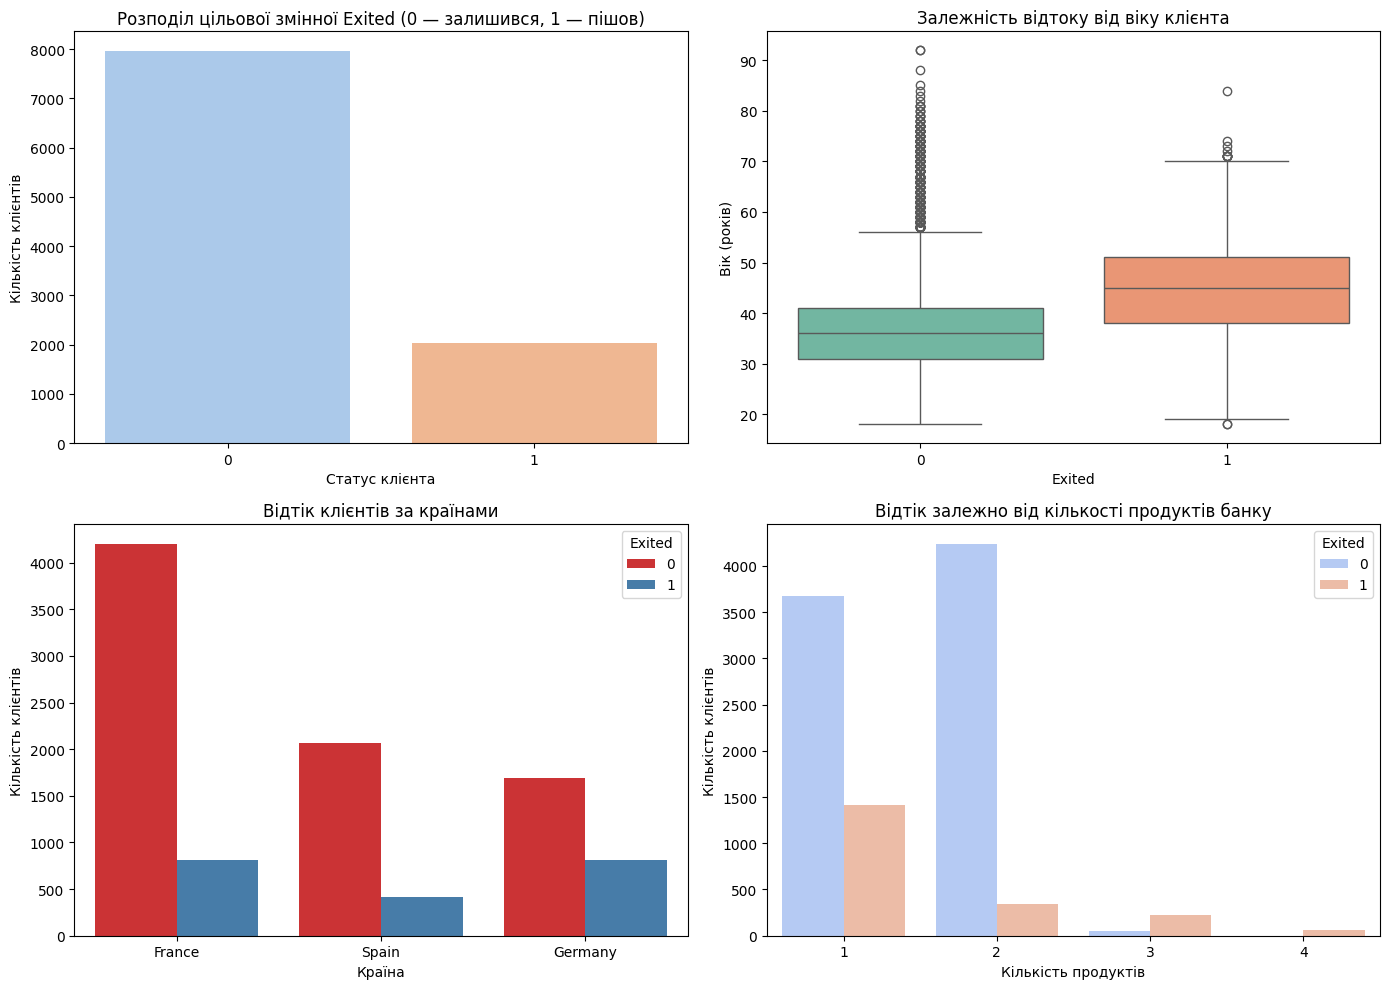

In [3]:
# Візуалізація основних закономірностей відтоку клієнтів банку
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Співвідношення клієнтів, які залишилися (0) та пішли (1)
sns.countplot(data=df, x='Exited', hue='Exited', palette='pastel', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Розподіл цільової змінної Exited (0 — залишився, 1 — пішов)')
axes[0, 0].set_xlabel('Статус клієнта')
axes[0, 0].set_ylabel('Кількість клієнтів')

# 2. Вік клієнтів та відтік
sns.boxplot(data=df, x='Exited', y='Age', hue='Exited', palette='Set2', legend=False, ax=axes[0, 1])
axes[0, 1].set_title('Залежність відтоку від віку клієнта')
axes[0, 1].set_xlabel('Exited')
axes[0, 1].set_ylabel('Вік (років)')

# 3. Відтік за країнами
sns.countplot(data=df, x='Geography', hue='Exited', palette='Set1', ax=axes[1, 0])
axes[1, 0].set_title('Відтік клієнтів за країнами')
axes[1, 0].set_xlabel('Країна')
axes[1, 0].set_ylabel('Кількість клієнтів')

# 4. Вплив кількості банківських продуктів
sns.countplot(data=df, x='NumOfProducts', hue='Exited', palette='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title('Відтік залежно від кількості продуктів банку')
axes[1, 1].set_xlabel('Кількість продуктів')
axes[1, 1].set_ylabel('Кількість клієнтів')

plt.tight_layout()
plt.show()

3. Підготовка даних

In [4]:
# Видаляємо службові стовпці, які не впливають на поведінку клієнта
df_prep = df.drop(columns=['RowNumber', 'CustomerId', 'Surname']).copy()

# Відокремлюємо ознаки та цільову змінну
X = df_prep.drop(columns=['Exited'])
y = df_prep['Exited']

# Кодування категоріальних ознак (Geography, Gender)
X_encoded = pd.get_dummies(X, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

# Розбиття на навчальну (80%) та тестову (20%) вибірки зі збереженням балансу класів
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Масштабування числових стовпців за допомогою RobustScaler
num_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
scaler = RobustScaler()

X_train = X_train.copy()
X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Розмір навчальної вибірки: (8000, 11)
Розмір тестової вибірки: (2000, 11)


4. Реалізація та порівняння моделей

Результати базових моделей на тестовому наборі:


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gradient Boosting,0.870,0.7928,0.4889,0.6049,0.8708
1,Random Forest,0.863,0.7759,0.4595,0.5772,0.8523
2,Extra Trees,0.860,0.7679,0.4472,0.5652,0.8457
3,Logistic Regression,0.808,0.5891,0.1867,0.2836,0.7748


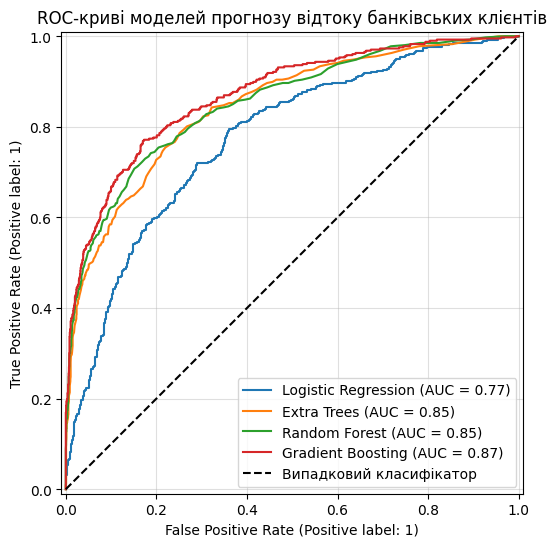

In [5]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Extra Trees': ExtraTreesClassifier(n_estimators=200, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

fitted_models = {}
results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    fitted_models[name] = clf

    y_pred = clf.predict(X_test)
    y_prob = clf.predict_proba(X_test)[:, 1]

    results.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
print("Результати базових моделей на тестовому наборі:")
display(comparison_df.round(4))

# Графік ROC-кривих
fig, ax = plt.subplots(figsize=(8, 6))
for name, clf in fitted_models.items():
    RocCurveDisplay.from_estimator(clf, X_test, y_test, name=name, ax=ax)

plt.plot([0, 1], [0, 1], 'k--', label='Випадковий класифікатор')
plt.title('ROC-криві моделей прогнозу відтоку банківських клієнтів')
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

5. Підбір параметрів та вибір найкращої моделі

Найкращі параметри: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 100}
CV ROC-AUC:       0.8649
Тестовий Accuracy: 0.8700
Тестовий F1-score: 0.6049
Тестовий ROC-AUC:  0.8708

Звіт класифікації найкращої моделі:
                precision    recall  f1-score   support

Залишиться (0)       0.88      0.97      0.92      1593
      Піде (1)       0.79      0.49      0.60       407

      accuracy                           0.87      2000
     macro avg       0.84      0.73      0.76      2000
  weighted avg       0.86      0.87      0.86      2000



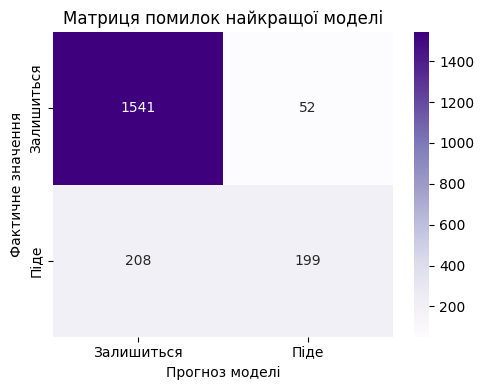

In [6]:
# Підбір гіперпараметрів для Gradient Boosting через GridSearchCV
param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 4],
    'min_samples_split': [2, 10]
}

grid_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
y_best_pred = best_model.predict(X_test)
y_best_prob = best_model.predict_proba(X_test)[:, 1]

print("Найкращі параметри:", grid_search.best_params_)
print(f"CV ROC-AUC:       {grid_search.best_score_:.4f}")
print(f"Тестовий Accuracy: {accuracy_score(y_test, y_best_pred):.4f}")
print(f"Тестовий F1-score: {f1_score(y_test, y_best_pred):.4f}")
print(f"Тестовий ROC-AUC:  {roc_auc_score(y_test, y_best_prob):.4f}")

print("\nЗвіт класифікації найкращої моделі:")
print(classification_report(y_test, y_best_pred, target_names=['Залишиться (0)', 'Піде (1)']))

# Матриця помилок
plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_best_pred),
    annot=True, fmt='d', cmap='Purples',
    xticklabels=['Залишиться', 'Піде'],
    yticklabels=['Залишиться', 'Піде']
)
plt.title('Матриця помилок найкращої моделі')
plt.xlabel('Прогноз моделі')
plt.ylabel('Фактичне значення')
plt.tight_layout()
plt.show()

6. Прогноз для конкретного клієнта

In [7]:
def predict_bank_client(client_data: dict, model=best_model):
    client_df = pd.DataFrame([client_data])
    client_encoded = pd.get_dummies(client_df, columns=['Geography', 'Gender'], dtype=int)
    client_aligned = client_encoded.reindex(columns=X_train.columns, fill_value=0)
    client_aligned[num_cols] = scaler.transform(client_aligned[num_cols])

    pred = model.predict(client_aligned)[0]
    prob_leave = model.predict_proba(client_aligned)[0][1]

    result_text = "КЛІЄНТ ПІДЕ З БАНКУ" if pred == 1 else "КЛІЄНТ ЗАЛИШИТЬСЯ В БАНКУ"
    print("=" * 50)
    print(f"Результат: {result_text}")
    print(f"Імовірність відтоку: {prob_leave * 100:.2f}%")
    print(f"Імовірність залишитися: {(1 - prob_leave) * 100:.2f}%")
    print("=" * 50)

# Дані клієнта для перевірки (можна змінювати параметри)
client_example = {
    'CreditScore': 610,             # Кредитний рейтинг (350 - 850)
    'Geography': 'Germany',         # 'France', 'Spain' або 'Germany'
    'Gender': 'Female',             # 'Male' або 'Female'
    'Age': 46,                      # Вік клієнта
    'Tenure': 2,                    # Скільки років обслуговується в банку (0 - 10)
    'Balance': 125000.0,            # Баланс на рахунку
    'NumOfProducts': 1,             # Кількість банківських продуктів (1 - 4)
    'HasCrCard': 1,                 # Наявність кредитної картки (1 — так, 0 — ні)
    'IsActiveMember': 0,            # Активний клієнт (1 — так, 0 — ні)
    'EstimatedSalary': 98000.0      # Орієнтовна річна зарплата
}

predict_bank_client(client_example)

Результат: КЛІЄНТ ПІДЕ З БАНКУ
Імовірність відтоку: 77.60%
Імовірність залишитися: 22.40%


##7. Висновки

Для виконання завдання я завантажив із Kaggle датасет про клієнтів банку на 10 000 записів, де під час перевірки не знайшов жодних пропусків, але побачив дисбаланс класів — близько 80% людей залишаються в банку, а 20% йдуть. На етапі підготовки даних я видалив непотрібні стовпці з номером рядка, ID та прізвищем клієнта, перевів стать і країну в числовий вигляд, поділив вибірку у пропорції 80 на 20 та масштабував числові ознаки. Серед чотирьох протестованих алгоритмів найкраще себе показав градієнтний бустинг, який випередив випадковий ліс, Extra Trees та логістичну регресію. Підбір гіперпараметрів через GridSearchCV підтвердив оптимальність налаштувань для Gradient Boosting, і ця модель показала на тестовій вибірці точність 87% та ROC-AUC 0,8708. Наприкінці я ввів дані окремого клієнта з Німеччини та отримав прогноз, що він піде з банку з імовірністю 77,60%.